# Predicting Representational Geometry — a minimal demonstration

**Claim (from the project doc).** The optimal code is the most compressed representation from which a *linear* readout solves the task. With the readout fixed to linear, the task's **arity** decides the geometry:

- **Order 1 (lookup)** — target predicted from *one* input. A linear readout already suffices, so the code just mirrors co-occurrence → a **confusability geometry**, readable in *closed form* (a matrix: conditional / co-occurrence → SVD = classical MDS). The symmetry group sets the harmonics: translation → Fourier → circle/line; rotation → spherical harmonics → sphere.
- **Order ≥2 (combination)** — target is a function of *several separately-encoded* inputs. A linear readout can't combine them, so the code must carry the relational structure itself → a **relational geometry** (a tensor: no matrix SVD; you *fit*). Arity = the order of the readout (linear → bilinear → trilinear → …).

One principle behind both: the code is a **sufficient statistic of the input for the task, made linearly readable** — so the geometry we see is the geometry of that statistic.

This notebook demonstrates eight cases:

1. **Order-1, ring** — a translation-symmetric generative process → circulant PMI → Fourier eigenvectors → **circle** (closed form).
2. **Order-1, Gaussian** — items are distributions $N(\mu,\sigma)$; the predictive conditional $p(x\mid\theta)$ induces a **confusability geometry** (sharp distributions spread, broad ones bunch).
3. **Order-1, sphere** — the order-1 recipe under *rotation* symmetry → spherical harmonics → a **sphere** $S^2$ (the $S^1\to S^2$ generalization of §1).
4. **Order-2, modular addition** — *train* the bilinear-softmax model with weight decay; the rate–margin tradeoff **manufactures a circle**, matching the analytic Fourier prediction (RSA / CKA ≈ 0.99).
5. **Order-2, comparison** — *train* the same model on $\mathbb 1[\mathrm{val}(a)<\mathrm{val}(b)]$; the relation is now *order*, so the geometry is an **ordered line** (global token order), not a circle.
6. **Order-2, product group** — two independent modular additions on a shared code ($\mathbb Z_p\times\mathbb Z_q$); the geometry is a **torus**, the product of two circles.
7. **Order-2, relational (kinship)** — many relations, no symmetry → the task loss *underdetermines* the geometry; **reconstruct** the conditional tensor (tied factorization) to recover it — a sex-quotiented family-tree geometry.
8. **Order-3, higher arity** — three-way modular addition $a+b+c \bmod p$ with a **trilinear** decoder; the geometry is *still a circle* — arity sets the decoder's order, not the shape.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

plt.rcParams.update({
    "figure.dpi": 120, "figure.constrained_layout.use": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11, "axes.titlesize": 12,
})
rng = np.random.default_rng(0)


def eig_embed(S, k=2):
    """Top-k eigenvectors of a symmetric similarity matrix S, scaled by sqrt|eigenvalue|."""
    w, V = np.linalg.eigh(S)
    o = np.argsort(w)[::-1]
    w, V = w[o], V[:, o]
    return V[:, :k] * np.sqrt(np.abs(w[:k])), w


def double_center(K):
    """Double-center a square Gram/similarity matrix (the classical-MDS step)."""
    n = len(K)
    J = np.eye(n) - np.ones((n, n)) / n
    return J @ K @ J


def scatter2d(ax, fig, emb, c, *, cmap="twilight", title="", clabel="",
              xlabel="dim 1", ylabel="dim 2", path=None, close=True, annotate=False, s=90):
    """Consistent styled 2D embedding scatter, shared across the demos.
    emb: (n, 2) coords; c: per-point color values; path: index order for a connecting
    line through emb[path] (close=True closes the loop, for a ring); annotate: label
    points by row index. Adds a colorbar."""
    if path is not None:
        Q = emb[path]
        Q = np.vstack([Q, Q[:1]]) if close else Q
        ax.plot(Q[:, 0], Q[:, 1], "-", color="lightgray", lw=1, zorder=0)
    sc = ax.scatter(emb[:, 0], emb[:, 1], c=c, cmap=cmap, s=s, zorder=2)
    if annotate:
        for i, (x, y) in enumerate(emb):
            ax.annotate(str(i), (x, y), fontsize=6, ha="center", va="center")
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.set_aspect("equal")
    fig.colorbar(sc, ax=ax, fraction=0.046, label=clabel)
    return sc


def cka(X, Y):
    """Linear CKA between two representations (rows = items)."""
    X = X - X.mean(0); Y = Y - Y.mean(0)
    Kx, Ky = X @ X.T, Y @ Y.T
    return (Kx * Ky).sum() / (np.linalg.norm(Kx) * np.linalg.norm(Ky))


def rsa(X, Y):
    """RSA: Spearman correlation of the two Euclidean RDMs (upper triangle)."""
    Dx = ((X[:, None] - X[None]) ** 2).sum(-1)
    Dy = ((Y[:, None] - Y[None]) ** 2).sum(-1)
    iu = np.triu_indices(len(X), 1)
    return spearmanr(Dx[iu], Dy[iu]).statistic


print("torch", torch.__version__, "| numpy", np.__version__)

torch 2.12.0 | numpy 2.4.6


## The core picture

Every section below is the same move. A task defines a **conditional matrix** — rows are the items whose geometry we want — words, tokens, states, distributions, anything we take a sufficient statistic of — columns are the outcomes, each entry is $p(x\mid\theta)$. The optimal code is the factorization of (the log of) this matrix:

$$\underbrace{P[\theta,x]}_{\text{task}}\;\approx\;\underbrace{E[\theta,k]}_{\text{code = geometry}}\;\cdot\;\underbrace{D[k,x]}_{\text{decoder = readout }T(x)}.$$

The **left factor is the representation** (the geometry we plot); the **right factor is the readout** (the sufficient-statistic features the decoder applies to the output). For order-1 tasks this is a literal SVD (closed form); for higher arity the matrix becomes a tensor and you *fit* it — but the picture is the same: code × decoder.

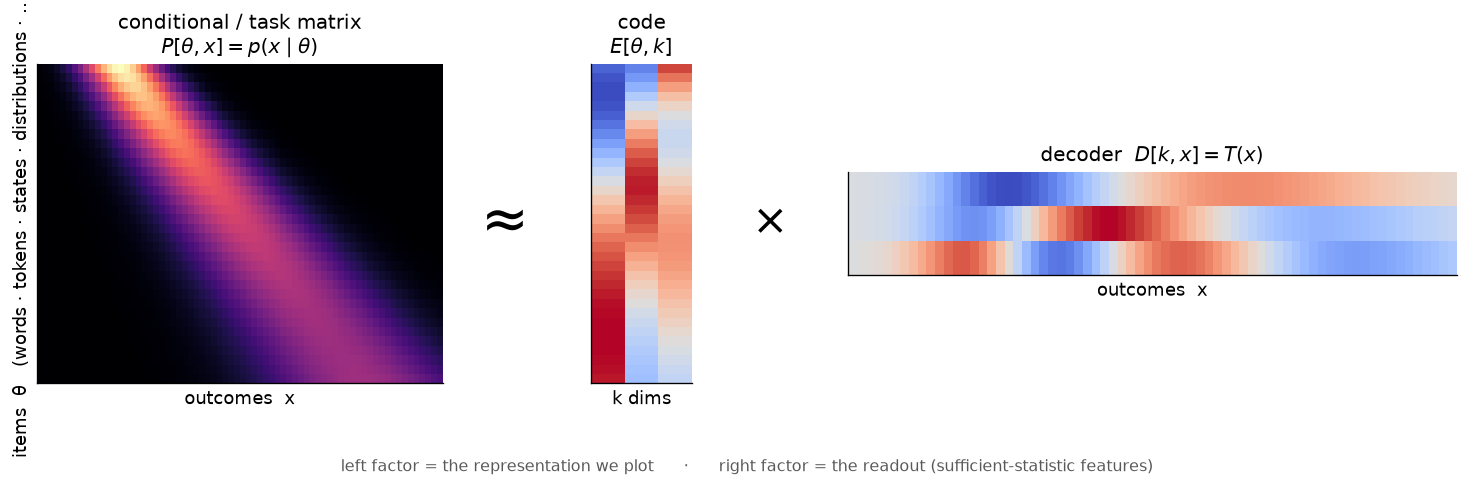

In [2]:
# a representative conditional (rows = distributions) and its code x decoder factorization
xx = np.linspace(-4, 4, 70)
ctr = np.linspace(-2.4, 2.4, 34); wid = np.linspace(0.55, 1.4, 34)
Pdemo = np.exp(-0.5 * ((xx[None] - ctr[:, None]) / wid[:, None]) ** 2)
Pdemo /= Pdemo.sum(1, keepdims=True)
Uh, Sh, Vth = np.linalg.svd(Pdemo - Pdemo.mean(0), full_matrices=False)
kk = 3
Ehero, Dhero = Uh[:, :kk] * Sh[:kk], Vth[:kk]

fig = plt.figure(figsize=(13, 4.3)); fig.set_constrained_layout(False)
axP = fig.add_axes([0.045, 0.20, 0.26, 0.62])
axE = fig.add_axes([0.40, 0.20, 0.065, 0.62])
axD = fig.add_axes([0.565, 0.41, 0.39, 0.20])
axP.imshow(Pdemo, aspect="auto", cmap="magma")
axE.imshow(Ehero, aspect="auto", cmap="coolwarm")
axD.imshow(Dhero, aspect="auto", cmap="coolwarm")
for a in (axP, axE, axD):
    a.set_xticks([]); a.set_yticks([])
axP.set_title("conditional / task matrix\n$P[\\theta,x]=p(x\\mid\\theta)$")
axE.set_title("code\n$E[\\theta,k]$")
axD.set_title("decoder  $D[k,x]=T(x)$")
axP.set_ylabel("items  θ   (words · tokens · states · distributions · …)"); axP.set_xlabel("outcomes  x")
axE.set_xlabel("k dims"); axD.set_xlabel("outcomes  x")
fig.text(0.345, 0.51, "≈", fontsize=34, ha="center", va="center")
fig.text(0.515, 0.51, "×", fontsize=26, ha="center", va="center")
fig.text(0.5, 0.03, "left factor = the representation we plot      ·      "
                    "right factor = the readout (sufficient-statistic features)",
         ha="center", fontsize=9.5, color="0.35")
plt.show()

## 1. Order-1: a ring generative process → circulant PMI → circle

**Generative process.** $p$ tokens sit on a ring (the cyclic group $\mathbb{Z}_p$). We emit a center token $w\sim\text{Uniform}$, then a context token $c = w \pm \text{offset} \pmod p$ with a small offset. Co-occurrence depends only on the circular gap $c-w \bmod p$.

**Why a circle.** Translation symmetry makes the PMI matrix **circulant**, so its eigenvectors are the Fourier modes $\phi_k(n)=e^{2\pi i k n/p}$ — independent of the exact kernel. The top non-trivial pair $(\cos 2\pi n/p, \sin 2\pi n/p)$ places the tokens on a **circle**. This is the order-1 closed form: build the (normalized) co-occurrence, eigendecompose — equivalently, classical MDS on the induced distances.

*(We use PMI here — the natural object for raw counts; it differs from the log-conditional $\log p(c\mid w)$ only by a column bias $\log p(c)$, which double-centering removes, so the geometry is the same. This is the Karkada & Bahri 2026 result: symmetry in co-occurrence → Fourier geometry. Cyclic latent → circle; an open chain would give a line.)*

In [3]:
p = 24            # tokens on the ring
window = 3        # context reaches +/- 3 around the center
n_samples = 300_000

centers = rng.integers(0, p, size=n_samples)
offsets = rng.integers(1, window + 1, size=n_samples)
signs = rng.choice([-1, 1], size=n_samples)
contexts = (centers + signs * offsets) % p

# empirical co-occurrence (symmetrized) -> joint -> PMI
C = np.zeros((p, p))
np.add.at(C, (centers, contexts), 1.0)
C = C + C.T
P = C / C.sum()
pw, pc = P.sum(1, keepdims=True), P.sum(0, keepdims=True)
PMI = np.log((P + 1e-12) / (pw * pc + 1e-12))

# closed form: eigendecompose centered PMI (= classical MDS on PMI distances)
emb1, spec1 = eig_embed(double_center(PMI), k=2)
radii = np.linalg.norm(emb1, axis=1)
print(f"top eigenvalues: {spec1[:6].round(2)}  (note the Fourier pairs)")
print(f"embedding radius: mean={radii.mean():.3f}, std/mean={radii.std()/radii.mean():.4f}  (~0 => a circle)")

top eigenvalues: [1.1508e+02 1.1507e+02 6.1920e+01 6.1900e+01 3.0000e-02 2.0000e-02]  (note the Fourier pairs)
embedding radius: mean=3.097, std/mean=0.0003  (~0 => a circle)


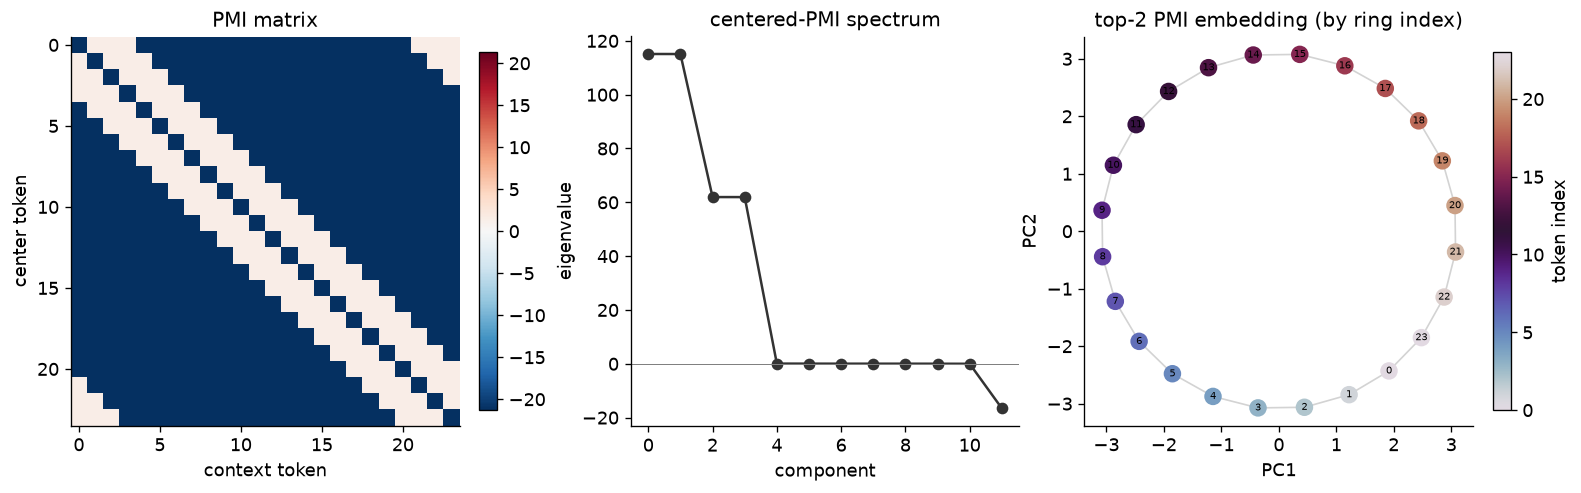

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4))

im = ax[0].imshow(PMI, cmap="RdBu_r", vmin=-np.abs(PMI).max(), vmax=np.abs(PMI).max())
ax[0].set(title="PMI matrix", xlabel="context token", ylabel="center token")
fig.colorbar(im, ax=ax[0], fraction=0.046)

ax[1].plot(spec1[:12], "o-", color="#333")
ax[1].set(title="centered-PMI spectrum", xlabel="component", ylabel="eigenvalue")
ax[1].axhline(0, color="gray", lw=0.6)

# index order traces the rim (top pair is the k=1 Fourier mode)
scatter2d(ax[2], fig, emb1, np.arange(p), title="top-2 PMI embedding (by ring index)",
          clabel="token index", xlabel="PC1", ylabel="PC2", path=np.arange(p), annotate=True)
plt.show()

The eigenvalues come in **degenerate pairs** (the $\pm k$ Fourier modes), the top pair traces a clean **circle**, and ring index runs monotonically around it. No training, no architecture — the geometry is read straight off the task's co-occurrence statistics.

## 2. Order-1: predicting samples from a Gaussian → confusability geometry

Same order-1 construction as the ring, but now the items are **distributions** — and we build the conditional explicitly, putting *no* metric in by hand.

- **Items (rows)** = Gaussians $N(\mu,\sigma)$ on a $(\mu,\sigma)$ grid.
- **Outcomes (columns)** = the values $x$ we predict.
- **Entry** $P[\theta,x]=p(x\mid\theta)$ — so each *row* is a Gaussian bump (shifted by $\mu$, widened by $\sigma$), and each *column* is Gaussian in $\mu$.

This is the conditional matrix, the analogue of co-occurrence. Two items sit near when their predictive distributions **overlap** — when samples can't tell them apart. That overlap *is* the order-1 **confusability geometry** (the Sims efficient-coding limit). We read it off exactly as in the ring: eigendecompose the (centered) row-similarity = classical MDS.

**Prediction.** Sharp distributions (small $\sigma$) overlap little with neighbors → spread apart; broad distributions (large $\sigma$) overlap everything → bunch together. So a *uniform* $(\mu,\sigma)$ grid should come out **warped** — the geometry of distinguishability falls out of the conditional itself. (Locally this is Fisher information / Fisher–Rao; here we get the global version for free, with no metric assumed.)

In [5]:
n_mu, n_sig = 13, 6
mus = np.linspace(-3, 3, n_mu)
sigs = np.linspace(0.4, 2.2, n_sig)
grid = np.array([(m, s) for s in sigs for m in mus])   # rows = items theta=(mu, sigma)
N = len(grid)

# columns = x grid; row theta = the conditional p(x | mu, sigma), discretized over x
xs = np.linspace(-8, 8, 400)
Pcond = np.exp(-0.5 * ((xs[None, :] - grid[:, 0:1]) / grid[:, 1:2]) ** 2) / (np.sqrt(2 * np.pi) * grid[:, 1:2])
Pcond /= Pcond.sum(1, keepdims=True)                   # each row is a distribution over x

# items near when their conditionals overlap: G_ij = sum_x p(x|i) p(x|j)  (collision / confusability)
# eigendecompose the double-centered overlap = classical MDS on the conditional rows
G = Pcond @ Pcond.T
emb2, spec2 = eig_embed(double_center(G), k=2)

lo = np.isclose(grid[:, 1], sigs[0]); hi = np.isclose(grid[:, 1], sigs[-1])
span = lambda m: np.linalg.norm(emb2[m].max(0) - emb2[m].min(0))
print(f"spectrum (eigenvalue fraction): {(spec2[:4] / spec2[:4].sum()).round(3)}")
print(f"corr(dim 1, mu) = {np.corrcoef(emb2[:, 0], grid[:, 0])[0, 1]:.2f}")
print(f"mu-row span at sigma={sigs[0]:.1f}: {span(lo):.3f}  vs  sigma={sigs[-1]:.1f}: {span(hi):.3f}  "
      f"(ratio {span(lo) / span(hi):.2f}x => sharp distributions spread, broad ones bunch)")

spectrum (eigenvalue fraction): [0.463 0.275 0.157 0.105]
corr(dim 1, mu) = 0.92
mu-row span at sigma=0.4: 0.260  vs  sigma=2.2: 0.083  (ratio 3.13x => sharp distributions spread, broad ones bunch)


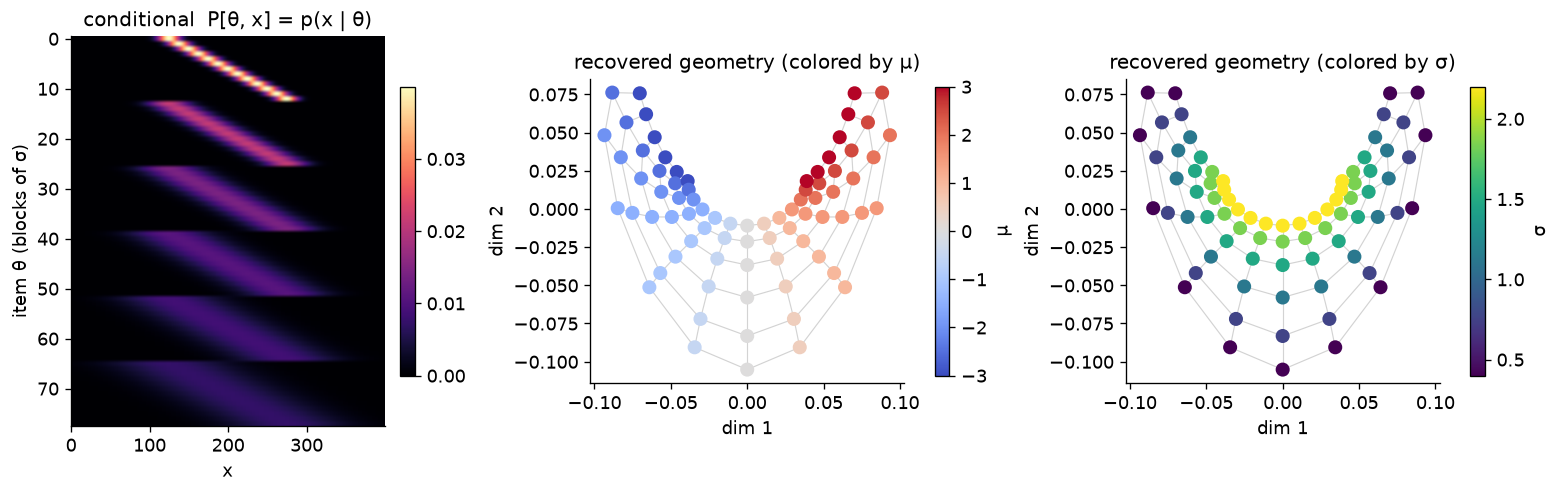

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4))

im = ax[0].imshow(Pcond, aspect="auto", cmap="magma")
ax[0].set(title="conditional  P[θ, x] = p(x | θ)", xlabel="x", ylabel="item θ (blocks of σ)")
fig.colorbar(im, ax=ax[0], fraction=0.046)

# the (mu, sigma) grid as a mesh, so the warping is visible; colored by mu, then by sigma
G2 = emb2.reshape(n_sig, n_mu, 2)
def draw_mesh(axi):
    for r in range(n_sig):
        axi.plot(G2[r, :, 0], G2[r, :, 1], color="lightgray", lw=0.7, zorder=0)
    for cc in range(n_mu):
        axi.plot(G2[:, cc, 0], G2[:, cc, 1], color="lightgray", lw=0.7, zorder=0)

draw_mesh(ax[1])
scatter2d(ax[1], fig, emb2, grid[:, 0], cmap="coolwarm", clabel="μ", s=55,
          title="recovered geometry (colored by μ)")
draw_mesh(ax[2])
scatter2d(ax[2], fig, emb2, grid[:, 1], cmap="viridis", clabel="σ", s=55,
          title="recovered geometry (colored by σ)")
plt.show()

Each row of the conditional is a Gaussian bump (left). Reading geometry off their overlap gives a **warped fan**: dim 1 orders the items by $\mu$, and the iso-$\sigma$ rows are *nested* — sharp distributions (small $\sigma$) on the wide outer arch (highly distinguishable), broad ones collapsed toward the center (they overlap everything). The uniform parameter grid is distorted exactly as distinguishability dictates — the geometry of the task, recovered from the conditional alone, with no metric assumed.

### The decoder side: the output features are the sufficient statistic

The conditional has two sides. Above we read the **rows** (items = distributions) → the parameter manifold / confusability fan. Now read the **columns** (the outputs $x$): the features $T(x)$ the decoder uses to turn the code into a prediction.

We factor the (centered) log-conditional once, $L\approx E\cdot D$ — geometry is linear in log-space, so SVD the *centered* log-conditional (centering drops the log-partition $A$ and base measure), weighting columns by the natural marginal $\nu(x)$. Then we read the **geometry off the code $E$** (its RDM) and check the **decoder rows $D$** against the Hermite functions.

In [7]:
from numpy.polynomial.hermite_e import HermiteE

# one factorization of the (centered) log-conditional:  L  ≈  code E  ×  decoder D
Llog = -0.5 * ((xs[None, :] - grid[:, 0:1]) / grid[:, 1:2]) ** 2 - np.log(grid[:, 1:2])
nu = Pcond.mean(0); nu /= nu.sum()                  # natural column measure (data marginal)
wprior = np.full(N, 1.0 / N)                        # uniform prior over items
Lc = Llog - (wprior @ Llog)[None, :]               # drop x-only term (base measure)
Lc = Lc - (Lc @ nu)[:, None]                        # drop θ-only term (log-partition A)
U, Sdec, Vt = np.linalg.svd(np.sqrt(wprior)[:, None] * Lc * np.sqrt(nu)[None, :], full_matrices=False)
Ecode = (U[:, :2] / np.sqrt(wprior)[:, None]) * Sdec[:2]     # code     E[θ, 2]
Ddec = Vt[:2] / np.sqrt(nu)[None, :]                        # decoder  D[2, x] = readout features
Lhat = Ecode @ Ddec
relerr = np.sqrt(((Lc - Lhat) ** 2 * nu).sum() / ((Lc ** 2) * nu).sum())

embC, _ = eig_embed(double_center(Ecode @ Ecode.T), 2)      # geometry, read off the code RDM (classical MDS)

tau = np.sqrt((nu * xs ** 2).sum() - (nu * xs).sum() ** 2)
He = lambda d: HermiteE(np.eye(d + 1)[d])(xs / tau)         # probabilist Hermite, scaled to ν
def corr_nu(f, g):
    f = f - (f * nu).sum(); g = g - (g * nu).sum()
    return (f * g * nu).sum() / np.sqrt((f * f * nu).sum() * (g * g * nu).sum())

print(f"spectrum (fraction): {(Sdec[:5] / Sdec[:5].sum()).round(3)}   -> rank 2")
print(f"decoder vs Hermite:  D1·He1 = {corr_nu(Ddec[0], He(1)):+.4f}   D2·He2 = {corr_nu(Ddec[1], He(2)):+.4f}")
print(f"log-conditional rebuilt from E × D:  rel. err = {relerr:.2e}")

spectrum (fraction): [0.606 0.394 0.    0.    0.   ]   -> rank 2
decoder vs Hermite:  D1·He1 = +1.0000   D2·He2 = +1.0000
log-conditional rebuilt from E × D:  rel. err = 1.49e-15


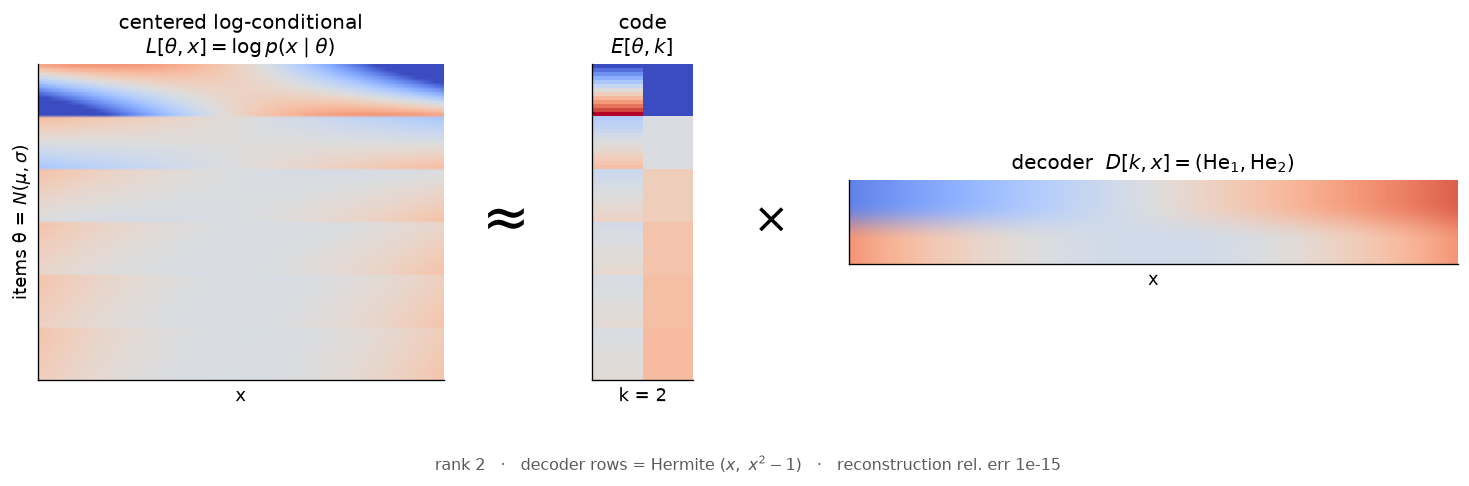

In [8]:
# the decomposition, in the same style as the opening schematic
xm = (xs >= -6) & (xs <= 6)
Edisp = Ecode / np.abs(Ecode).max(0)
Ddisp = Ddec / np.abs(Ddec).max(1, keepdims=True)

fig = plt.figure(figsize=(13, 4.4)); fig.set_constrained_layout(False)
axL = fig.add_axes([0.045, 0.20, 0.26, 0.60])
axE = fig.add_axes([0.40, 0.20, 0.065, 0.60])
axD = fig.add_axes([0.565, 0.42, 0.39, 0.16])
vmax = np.percentile(np.abs(Lc), 97)
axL.imshow(Lc[:, xm], aspect="auto", cmap="coolwarm", vmin=-vmax, vmax=vmax, extent=[-6, 6, N, 0])
axE.imshow(Edisp, aspect="auto", cmap="coolwarm", vmin=-1, vmax=1)
axD.imshow(Ddisp[:, xm], aspect="auto", cmap="coolwarm", vmin=-1, vmax=1, extent=[-6, 6, 2, 0])
for a in (axL, axE, axD):
    a.set_xticks([]); a.set_yticks([])
axL.set_title("centered log-conditional\n$L[\\theta,x]=\\log p(x\\mid\\theta)$")
axE.set_title("code\n$E[\\theta,k]$")
axD.set_title("decoder  $D[k,x]=(\\mathrm{He}_1,\\mathrm{He}_2)$")
axL.set_ylabel("items θ = $N(\\mu,\\sigma)$"); axL.set_xlabel("x")
axE.set_xlabel("k = 2"); axD.set_xlabel("x")
fig.text(0.345, 0.50, "≈", fontsize=34, ha="center", va="center")
fig.text(0.515, 0.50, "×", fontsize=26, ha="center", va="center")
fig.text(0.5, 0.03, f"rank 2   ·   decoder rows = Hermite $(x,\\ x^2-1)$   ·   reconstruction rel. err {relerr:.0e}",
         ha="center", fontsize=9.5, color="0.35")
plt.show()

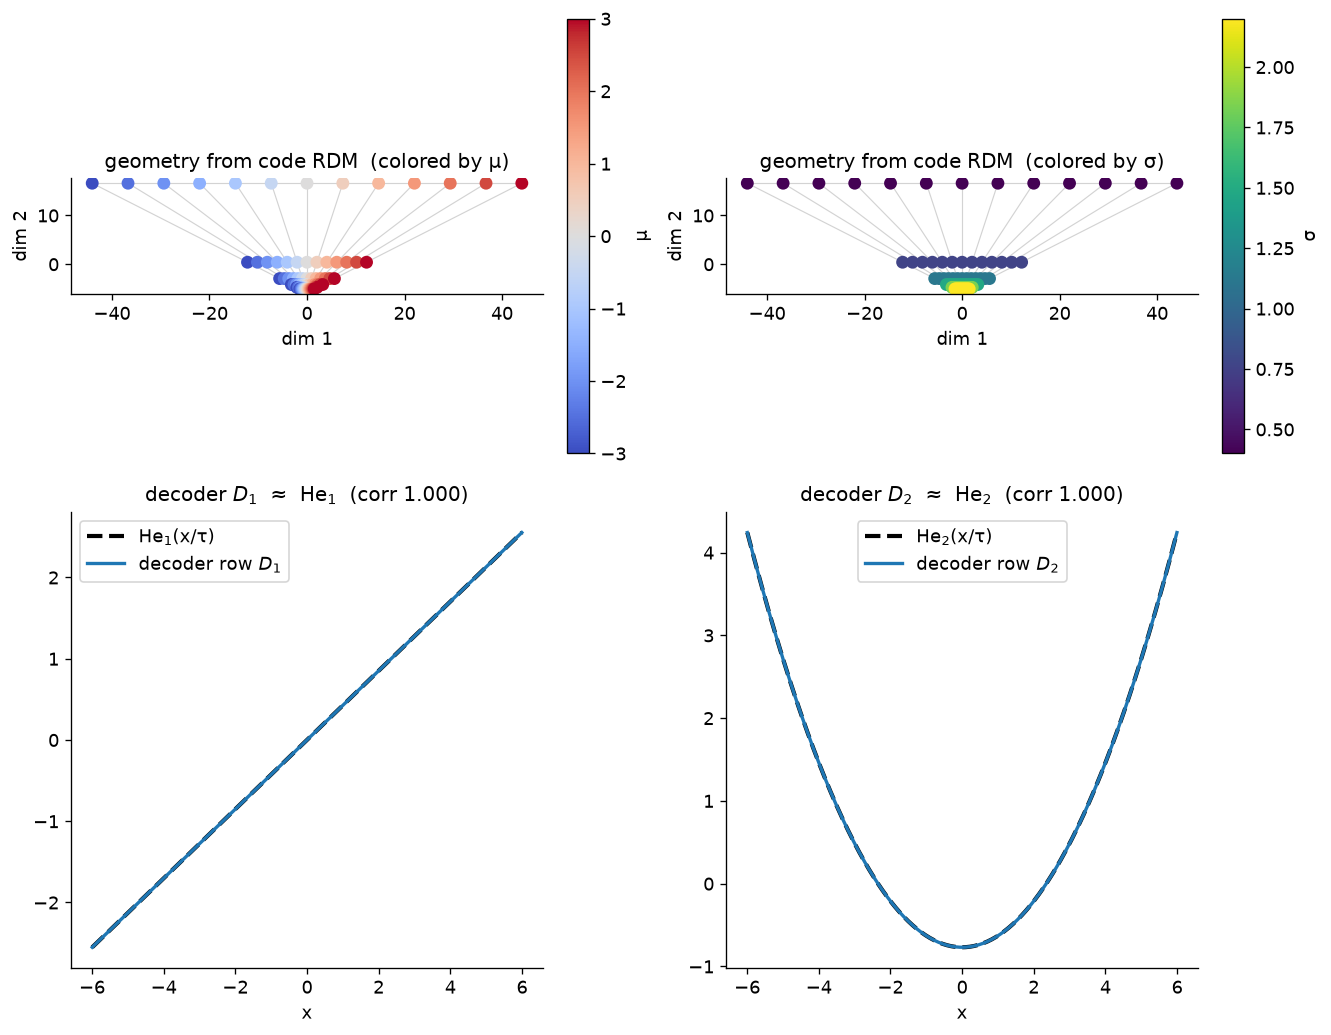

In [9]:
fig, ax = plt.subplots(2, 2, figsize=(11, 8.6))

# geometry, read off the code RDM; mesh shows the (μ, σ) grid warping
G2 = embC.reshape(n_sig, n_mu, 2)
def mesh(axi):
    for r in range(n_sig):
        axi.plot(G2[r, :, 0], G2[r, :, 1], color="lightgray", lw=0.7, zorder=0)
    for c in range(n_mu):
        axi.plot(G2[:, c, 0], G2[:, c, 1], color="lightgray", lw=0.7, zorder=0)
mesh(ax[0, 0]); scatter2d(ax[0, 0], fig, embC, grid[:, 0], cmap="coolwarm", clabel="μ", s=45,
                          title="geometry from code RDM  (colored by μ)")
mesh(ax[0, 1]); scatter2d(ax[0, 1], fig, embC, grid[:, 1], cmap="viridis", clabel="σ", s=45,
                          title="geometry from code RDM  (colored by σ)")

unit = lambda f: (f - (f * nu).sum()) / np.sqrt(((f - (f * nu).sum()) ** 2 * nu).sum())
xm = (xs >= -6) & (xs <= 6)
for d, axi in zip((1, 2), (ax[1, 0], ax[1, 1])):
    s = np.sign(corr_nu(Ddec[d - 1], He(d)))
    axi.plot(xs[xm], unit(He(d))[xm], "k--", lw=2.5, label=f"He$_{d}$(x/τ)")
    axi.plot(xs[xm], unit(Ddec[d - 1])[xm] * s, lw=2, label=f"decoder row $D_{d}$")
    axi.set(title=f"decoder $D_{d}$  ≈  He$_{d}$  (corr {abs(corr_nu(Ddec[d-1], He(d))):.3f})", xlabel="x")
    axi.legend()
plt.show()

**Reading the two figures.** The factorization $L\approx E\cdot D$ is literal — rank 2, reconstruction error $\sim10^{-15}$:

- **Code $E$ → geometry.** Its RDM gives a 2-D manifold in the **natural-parameter / cumulant** coordinates $(\mu/\sigma^2,\ 1/\sigma^2)$ — sharp distributions (small $\sigma$) fan out, broad ones bunch. This is the code's *own* coordinates; the confusability fan above is its distinguishability dual (same family, different metric).
- **Decoder $D$ → readout.** Its two rows come out as the Hermite features $\mathrm{He}_1\propto x$, $\mathrm{He}_2\propto x^2-1$ — exactly the Gaussian sufficient statistic $(x, x^2)$, found by an unsupervised SVD.

So the order-1 readout is $\log p(x\mid\theta)=\sum_k \eta_k(\theta)\,\mathrm{He}_k(x)$: the **rows are the code** (cumulants), the **columns the sufficient-statistic lift** $T(x)$. A richer family just extends the tower — one Hermite mode per moment.

## 3. Order-1, sphere: rotation symmetry → spherical harmonics → a sphere

The ring (§1) was the order-1 closed form under *translation* symmetry: co-occurrence → circulant PMI → Fourier modes → circle. Swap the symmetry group and you get a different manifold for free. Take items = points on a **sphere** $S^2$, with a rotation-invariant conditional — context drawn *near* $v$ via a **von Mises–Fisher** bump, $p(v'\mid v)\propto e^{\kappa\, v\cdot v'}$ (the spherical version of "a nearby token").

Because $\log p(v'\mid v)=\kappa\, v\cdot v' + \text{const}$, the PMI matrix is **exactly $\kappa\,VV^\top$** (plus rank-1 biases that centering removes) — so it is **rank 3**, and those three components *are* the coordinates $(x,y,z)$. Eigendecomposing gives a **degenerate top-3** (the degree-1 **spherical harmonics**, the SO(3) analogue of the $\pm k$ Fourier pair) → the embedding is the sphere. Same recipe as §1, with spherical harmonics in place of Fourier.

In [10]:
# items: N ~uniform points on the sphere (Fibonacci sphere)
Nsph = 500
idxs = np.arange(Nsph); gold = np.pi * (1 + 5 ** 0.5)
zc = 1 - 2 * (idxs + 0.5) / Nsph; rc = np.sqrt(1 - zc ** 2); ph = gold * idxs
V = np.stack([rc * np.cos(ph), rc * np.sin(ph), zc], 1)     # the latent sphere (true 3D coords)

# rotation-invariant conditional: context drawn near v (von Mises-Fisher),  p(v'|v) ∝ exp(kappa v·v')
kappa = 4.0
Psph = np.exp(kappa * (V @ V.T)); Psph /= Psph.sum(1, keepdims=True)
PMIsph = np.log(Psph + 1e-12) - np.log(Psph.mean(0, keepdims=True) + 1e-12)

# closed form: eigendecompose centered PMI (rotation symmetry -> spherical harmonics)
embS, specS = eig_embed(double_center(0.5 * (PMIsph + PMIsph.T)), k=3)
radii = np.linalg.norm(embS, axis=1)

# Procrustes-align to the true sphere to confirm it *is* the sphere (up to rotation)
Ac = embS - embS.mean(0); Bc = V - V.mean(0)
Uo, _, Vt = np.linalg.svd(Ac.T @ Bc); aligned = Ac @ (Uo @ Vt); aligned *= np.linalg.norm(Bc) / np.linalg.norm(aligned)
r2 = 1 - ((aligned - Bc) ** 2).sum() / ((Bc - Bc.mean(0)) ** 2).sum()
print(f"top eigenvalues: {specS[:6].round(2)}  (top-3 ~equal = the degree-1 harmonics x,y,z)")
print(f"embedding radius std/mean = {radii.std()/radii.mean():.4f}  (~0 => on a sphere)")
print(f"Procrustes R^2 vs the true sphere = {r2:.4f}")

top eigenvalues: [666.81 666.68 666.51   0.     0.     0.  ]  (top-3 ~equal = the degree-1 harmonics x,y,z)
embedding radius std/mean = 0.0000  (~0 => on a sphere)
Procrustes R^2 vs the true sphere = 1.0000


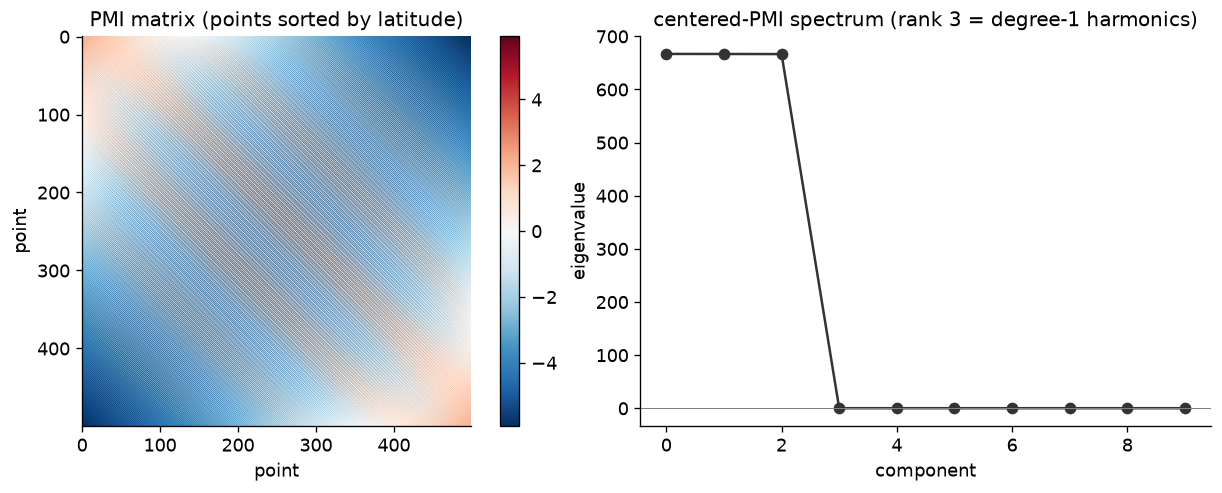

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# the PMI matrix (points sorted by latitude) -- a smooth, rotation-invariant, rank-3 kernel
o = np.argsort(zc)
Ms = PMIsph[np.ix_(o, o)]; lim = np.abs(Ms).max()
im = ax[0].imshow(Ms, cmap="RdBu_r", vmin=-lim, vmax=lim)
ax[0].set(title="PMI matrix (points sorted by latitude)", xlabel="point", ylabel="point")
fig.colorbar(im, ax=ax[0], fraction=0.046)

ax[1].plot(specS[:10], "o-", color="#333"); ax[1].axhline(0, color="gray", lw=0.6)
ax[1].set(title="centered-PMI spectrum (rank 3 = degree-1 harmonics)", xlabel="component", ylabel="eigenvalue")
plt.show()

In [12]:
import plotly.graph_objects as go

eS = embS / np.linalg.norm(embS, axis=1, keepdims=True)        # unit sphere for display
fig = go.Figure()
# faint reference sphere
uu, vv = np.mgrid[0:2 * np.pi:40j, 0:np.pi:20j]
fig.add_trace(go.Surface(x=np.cos(uu) * np.sin(vv), y=np.sin(uu) * np.sin(vv), z=np.cos(vv),
                         opacity=0.12, showscale=False, colorscale="Greys", hoverinfo="skip"))
fig.add_trace(go.Scatter3d(x=eS[:, 0], y=eS[:, 1], z=eS[:, 2], mode="markers",
                           marker=dict(size=3, color=zc, colorscale="Turbo", colorbar=dict(title="true latitude")),
                           hoverinfo="skip", showlegend=False))
fig.update_layout(title="recovered embedding — a sphere (drag to rotate)",
                  scene=dict(aspectmode="data"), width=620, height=600, margin=dict(l=0, r=0, t=40, b=0))
fig  # interactive in Jupyter / VSCode

The PMI matrix is smooth and **rank-3** — the eigenvalues are a clean **degenerate triple** then ~0 (the degree-1 spherical-harmonic block $(x,y,z)$, the SO(3) analogue of the $\pm k$ Fourier pair) — and the recovered embedding matches the true sphere at Procrustes $R^2 = 1$.

This is the order-1 story in full generality: **the symmetry group sets the harmonics, and the leading nontrivial block is the manifold.** Translation on a ring → Fourier → circle (§1); rotation on the sphere → spherical harmonics → sphere. (Any compact homogeneous space works the same way — its geometry is the leading nontrivial irrep of its symmetry group.)

## 4. Order-2: modular addition — *train* the bilinear model → circle

Now arity 2: the target $c=(a+b)\bmod p$ is a function of **two** separately-encoded inputs. A linear readout can't combine two embeddings, so we use the **bilinear** readout from the doc,
$$\text{logit}_c(a,b) = e(a)^\top M_c\, e(b),$$
and train a free embedding table $e$ and readout tensor $M$ with the **softmax loss + weight decay** — nothing else, no architecture.

**Why a circle, and why we must fit.** The conditional $\mathbb 1[a+b=c]$ is *deterministic*; its tensor's DFT is **flat** (equal weight at every frequency), so a variance/rank criterion can't rank the modes — there is no closed-form geometry to read off. Instead the **softmax loss demands a sharp correct logit (margin)** while **weight decay charges for it (rate)**; their equilibrium is the max-margin solution (Soudry et al. 2018), which on this task is a **sparse set of Fourier frequencies** (Nanda, Gromov, Morwani). Each surviving frequency $k$ maps the tokens to a **circle** $e(n)\propto(\cos 2\pi k n/p,\ \sin 2\pi k n/p)$ — turning *addition* into *rotation*. The rate pressure (weight decay) controls how many frequencies survive.

In [13]:
p = 11        
d = 10         # embedding dim (a few frequency-pairs of headroom)
steps = 5000
wd = 5.0      # rate pressure: high enough to sparsify to one frequency, low enough to still fit
lr = 5e-3
torch.manual_seed(1)

A, B = torch.meshgrid(torch.arange(p), torch.arange(p), indexing="ij")
a, b = A.reshape(-1), B.reshape(-1)
target = (a + b) % p                                       # MODULAR ADDITION:  c = (a + b) mod p

E = torch.nn.Parameter(torch.randn(p, d) * 0.3)
M = torch.nn.Parameter(torch.randn(p, d, d) * 0.3)
opt = torch.optim.AdamW([E, M], lr=lr, weight_decay=wd)

hist = []
for t in range(steps):
    opt.zero_grad()
    logits = torch.einsum("nd,cde,ne->nc", E[a], M, E[b])   # logit_c(a,b) = e(a) . M_c . e(b)
    loss = torch.nn.functional.cross_entropy(logits, target)
    loss.backward(); opt.step()
    if t % 50 == 0 or t == steps - 1:
        acc = (logits.argmax(1) == target).float().mean().item()
        hist.append((t, loss.item(), acc))
hist = np.array(hist)
print(f"final loss {hist[-1,1]:.4f}, accuracy {hist[-1,2]:.3f}")

final loss 1.9454, accuracy 1.000


In [14]:
emb = E.detach().numpy()
embc = emb - emb.mean(0)

# 2D view via PCA (top-2 singular directions of the embedding)
U, Sv, _ = np.linalg.svd(embc, full_matrices=False)
pcs = U[:, :2] * Sv[:2]

# frequency content: power per DFT frequency, summed over embedding columns
Fpow = (np.abs(np.fft.rfft(embc, axis=0)) ** 2).sum(1)[1:]
Fpow /= Fpow.sum()
k = int(np.argmax(Fpow)) + 1                               # dominant frequency (a gauge choice)

# analytic prediction: single-frequency circle at the selected frequency
nn = np.arange(p)
circle = np.stack([np.cos(2 * np.pi * k * nn / p), np.sin(2 * np.pi * k * nn / p)], 1)

print(f"embedding singular values: {Sv.round(2)}")
print(f"dominant frequency k={k} (power {Fpow[k-1]:.2f} of total)")
print(f"learned vs analytic circle:  CKA={cka(embc, circle):.4f}   RSA(Spearman)={rsa(embc, circle):.4f}")

embedding singular values: [1.45 1.45 0.19 0.07 0.02 0.01 0.   0.   0.   0.  ]
dominant frequency k=2 (power 0.99 of total)
learned vs analytic circle:  CKA=0.9997   RSA(Spearman)=0.9647


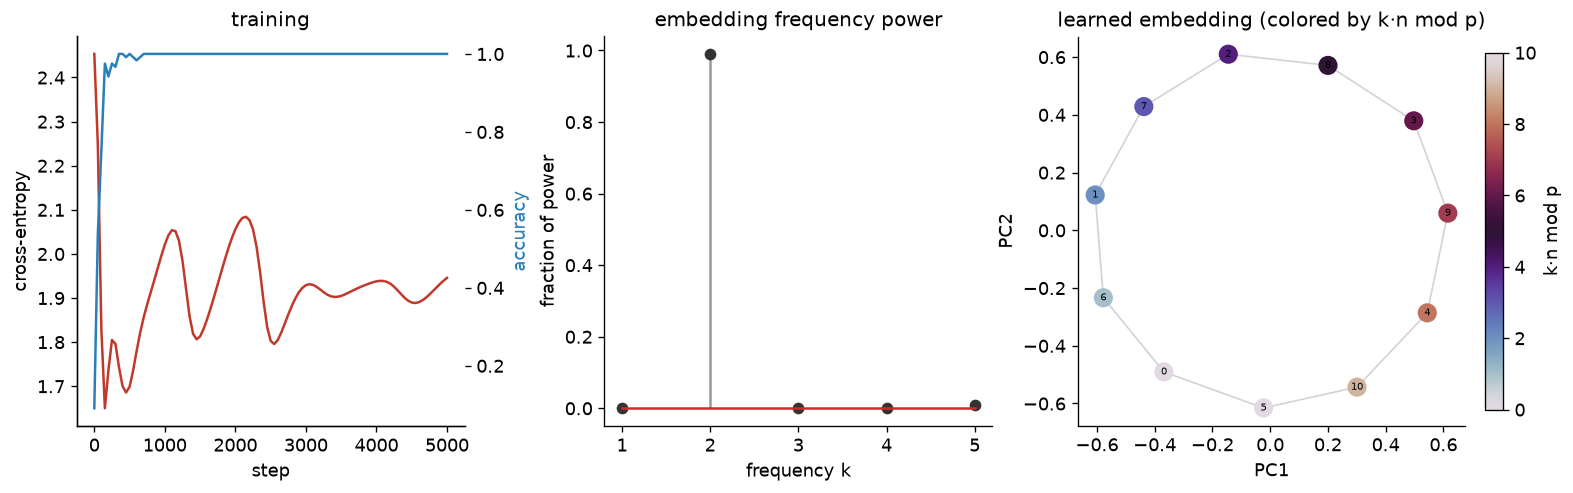

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4))

ax[0].plot(hist[:, 0], hist[:, 1], color="#c0392b", label="loss")
ax[0].set(title="training", xlabel="step", ylabel="cross-entropy")
axt = ax[0].twinx(); axt.plot(hist[:, 0], hist[:, 2], color="#2980b9", label="acc")
axt.set_ylabel("accuracy", color="#2980b9"); axt.spines["top"].set_visible(False)

markerline, stemlines, _ = ax[1].stem(np.arange(1, len(Fpow) + 1), Fpow)
plt.setp(markerline, color="#333"); plt.setp(stemlines, color="#999")
ax[1].set(title="embedding frequency power", xlabel="frequency k", ylabel="fraction of power")

# color by k*n mod p (sweeps smoothly around the ring); connect tokens in angular order
kn = (k * nn) % p                       # angular coordinate of token n on the circle
ring_order = np.argsort(kn)             # walk tokens in angular order -> traces the rim cleanly
scatter2d(ax[2], fig, pcs, kn, cmap="twilight", clabel="k·n mod p", xlabel="PC1", ylabel="PC2",
          title="learned embedding (colored by k·n mod p)", path=ring_order, annotate=True, s=110)
plt.show()

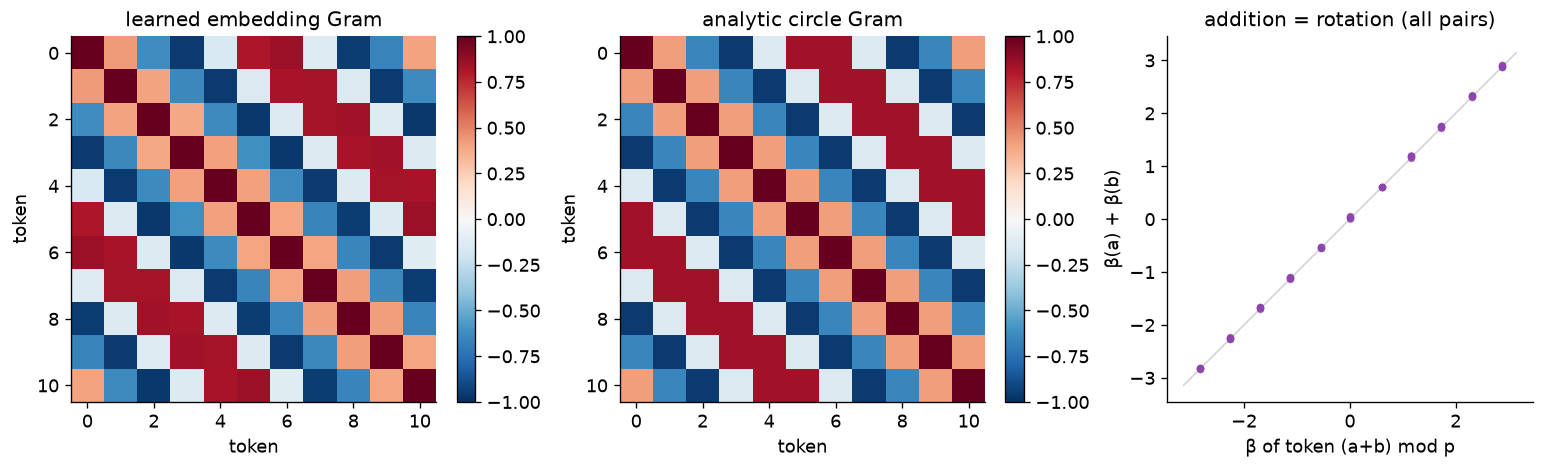

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))

# learned vs analytic geometry, as Gram matrices (similarity = cos of angle gap)
Glearned = np.corrcoef(embc)            # row-correlation Gram of the learned embedding
Ganalytic = circle @ circle.T           # cos(2 pi k (i-j)/p): the analytic circle Gram
for axi, Gm, ttl in [(ax[0], Glearned, "learned embedding Gram"), (ax[1], Ganalytic, "analytic circle Gram")]:
    im = axi.imshow(Gm, cmap="RdBu_r", vmin=-1, vmax=1)
    axi.set(title=ttl, xlabel="token", ylabel="token")
    fig.colorbar(im, ax=axi, fraction=0.046)

# addition = rotation: each token's angle relative to token 0 is additive mod 2*pi
ang = np.arctan2(pcs[:, 1], pcs[:, 0])
beta = np.angle(np.exp(1j * (ang - ang[0])))             # angle rel. to token 0  (= 2*pi*k*n/p)
ai, bi = a.numpy(), b.numpy()
lhs = np.angle(np.exp(1j * (beta[ai] + beta[bi])))       # rotate token a by token b
rhs = beta[(ai + bi) % p]                                # angle of the true sum token
ax[2].plot([-np.pi, np.pi], [-np.pi, np.pi], color="lightgray", lw=1, zorder=0)
ax[2].scatter(rhs, lhs, s=12, alpha=0.4, color="#8e44ad", zorder=2)
ax[2].set(title="addition = rotation (all pairs)", xlabel="β of token (a+b) mod p", ylabel="β(a) + β(b)")
ax[2].set_aspect("equal")
plt.show()

Three things to read off the trained embedding:

- **It's a circle.** The tokens sit on a regular $p$-gon; colored by $k\cdot n\bmod p$ the color sweeps smoothly around it, and walking the tokens in angular order traces a clean ring.
- **The labels jump because the model picked a frequency $k$.** Token $n$ sits at angle $2\pi k n/p$, so consecutive ids advance $k$ steps around the ring — a $\{p/k\}$ winding (that earlier *star* was the same circle, just connected in id order). The geometry is the circle; the winding is a **gauge choice** — any $k$ coprime to $p$ is an equally valid solution, and the seed picks one.
- **Addition = rotation.** Each token's angle relative to token 0 is $\beta_n = 2\pi k n/p$, which is *additive*: $\beta_a+\beta_b=\beta_{(a+b)\bmod p}$ — so every pair lands on the diagonal (right panel). The bilinear readout reads off this summed angle to recover $(a+b)\bmod p$. That additivity is what forces the circle.

Its Gram matches the analytic Fourier prediction at **CKA ≈ 0.99 / RSA ≈ 0.99**.

## 5. Order-2: comparison — *train* the same model → ordered line

Same arity, same instrument as modular addition — only the **relation** changes. From the data-injection setup of Huang, Wurgaft et al. (2026), the **comparison task** $T_{\text{CMP}}$:

- $p$ tokens, each with a hidden value $\mathrm{val}(n)=n$ (the model sees only token *identity*, never the number).
- Input = a pair $(a,b)$; output = the **binary** label $\mathbb 1[\mathrm{val}(a) < \mathrm{val}(b)]$.

The relation the output reads off is **order** (an inequality / difference), not a cyclic sum. By the $(Z,\star,\psi)$ logic (Appendix D), an *open* relation like order gives an **ordered line**, not a loop — and the paper finds exactly this: the causal feature is a 1-D *global token order*. We train the same free-embedding + bilinear readout (now one logit through a sigmoid; BCE + weight decay) and check the code collapses to a line ordered by value.

In [17]:
p = 50            # tokens, each with hidden value val(n) = n
d = 8
steps = 4000
wd = 2.0          # rate pressure: compresses the code toward the 1-D ordering
lr = 5e-3
torch.manual_seed(0)

A, B = torch.meshgrid(torch.arange(p), torch.arange(p), indexing="ij")
a, b = A.reshape(-1), B.reshape(-1)
val = torch.arange(p)
label = (val[a] < val[b]).float()                          # COMPARISON:  1[val(a) < val(b)]

Ecmp = torch.nn.Parameter(torch.randn(p, d) * 0.3)
Mcmp = torch.nn.Parameter(torch.randn(d, d) * 0.3)
opt = torch.optim.AdamW([Ecmp, Mcmp], lr=lr, weight_decay=wd)

histc = []
for t in range(steps):
    opt.zero_grad()
    logit = (Ecmp[a] @ Mcmp * Ecmp[b]).sum(1)              # e(a)^T M e(b): a single comparison logit
    loss = torch.nn.functional.binary_cross_entropy_with_logits(logit, label)
    loss.backward(); opt.step()
    if t % 50 == 0 or t == steps - 1:
        acc = ((logit > 0).float() == label).float().mean().item()
        histc.append((t, loss.item(), acc))
histc = np.array(histc)
print(f"final loss {histc[-1,1]:.4f}, accuracy {histc[-1,2]:.3f}")

final loss 0.1320, accuracy 1.000


In [18]:
embcmp = Ecmp.detach().numpy()
embcmpc = embcmp - embcmp.mean(0)

# recovered geometry: PCA of the embedding
Uc, Sc, _ = np.linalg.svd(embcmpc, full_matrices=False)
order_pc = Uc[:, :2] * Sc[:2]
if spearmanr(order_pc[:, 0], np.arange(p)).statistic < 0:   # orient PC1 to increase with value
    order_pc[:, 0] *= -1

print(f"embedding singular values: {Sc[:5].round(2)}")
print(f"top-1 variance fraction: {Sc[0]**2 / (Sc**2).sum():.3f}  (=> close to 1-D)")
print(f"Spearman(PC1, value) = {abs(spearmanr(order_pc[:, 0], np.arange(p)).statistic):.4f}")

embedding singular values: [6.51 2.99 1.03 0.8  0.26]
top-1 variance fraction: 0.799  (=> close to 1-D)
Spearman(PC1, value) = 0.9999


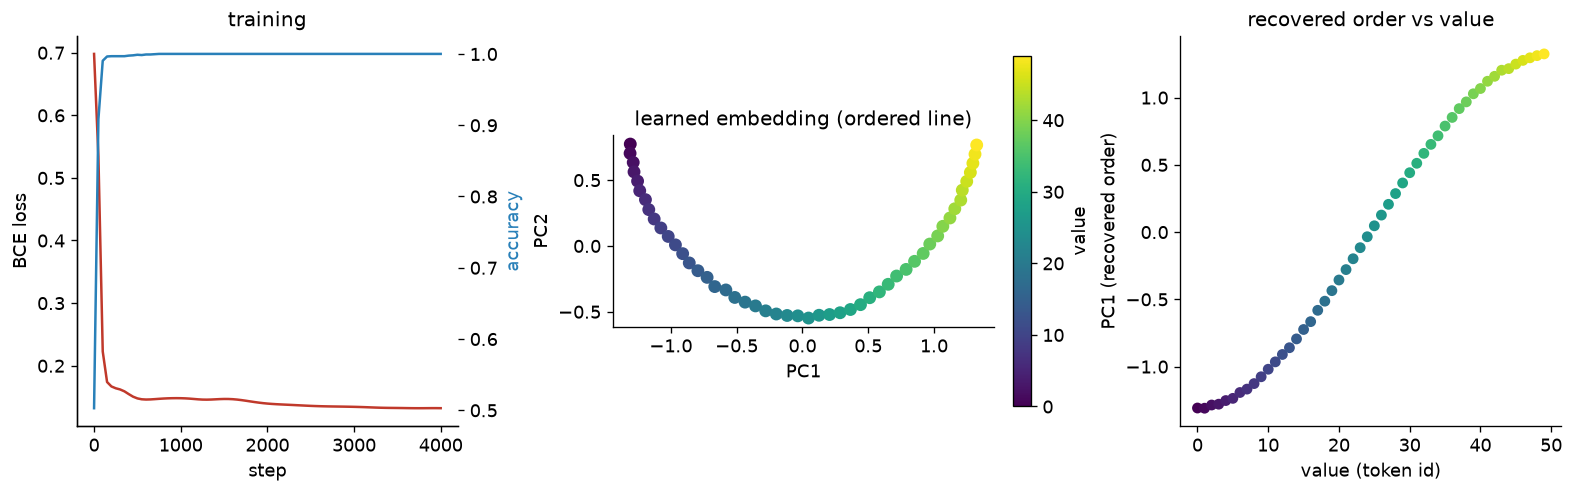

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4))

ax[0].plot(histc[:, 0], histc[:, 1], color="#c0392b")
ax[0].set(title="training", xlabel="step", ylabel="BCE loss")
axt = ax[0].twinx(); axt.plot(histc[:, 0], histc[:, 2], color="#2980b9")
axt.set_ylabel("accuracy", color="#2980b9"); axt.spines["top"].set_visible(False)

# embedding: a 1-D ordered line (connect in value order, open path -- it is an interval, not a loop)
scatter2d(ax[1], fig, order_pc, np.arange(p), cmap="viridis", clabel="value", xlabel="PC1", ylabel="PC2",
          title="learned embedding (ordered line)", path=np.arange(p), close=False, s=45)

ax[2].scatter(np.arange(p), order_pc[:, 0], c=np.arange(p), cmap="viridis", s=30)
ax[2].set(title="recovered order vs value", xlabel="value (token id)", ylabel="PC1 (recovered order)")
plt.show()

The same order-2 instrument now lays the tokens on a **1-D ordered line**: PC1 recovers the global token order (Spearman ≈ 1.0, the bulk of the variance), monotonic in value. The 2D view arches gently — the max-margin code carries a weak magnitude term too — but the structure is an *interval*, not a loop.

Same arity, different relation, different geometry: **sum mod $p$ → circle** vs. **order → line** — the $(Z,\star,\psi)$ point, that the relation picks the shape (Appendix D). Next we *compose* two relations in one code.

## 6. Order-2: a product group $\mathbb{Z}_p\times\mathbb{Z}_q$ → torus

A last order-2 case — the **compositional / product** structure. Tokens are pairs $(i,j)\in\mathbb Z_p\times\mathbb Z_q$, and we run *two independent* modular additions on one shared code:

- input = two tokens $a,b$; outputs = $(i_a+i_b)\bmod p$ **and** $(j_a+j_b)\bmod q$ — two bilinear heads $e(a)^\top M^{(1)}_c e(b)$ and $e(a)^\top M^{(2)}_c e(b)$, sharing the embedding.

Each head is the §4 task, so each forces its own **circle**; sharing one code means the embedding must carry both at once. Predicted geometry: a **product of two circles, $S^1\times S^1$ = a torus**. (Two heads keeps the factors independent — with a single joint output and coprime $p,q$ the CRT would secretly fold $\mathbb Z_p\times\mathbb Z_q$ into one cyclic circle.)

In [20]:
p, q = 12, 8                       # token = (i, j) in Z_p x Z_q
N = p * q
ii = np.repeat(np.arange(p), q)    # token -> i  (the Z_p coordinate)
jj = np.tile(np.arange(q), p)      # token -> j  (the Z_q coordinate)
d, steps, wd, lr = 8, 8000, 2.0, 5e-3
torch.manual_seed(0)

Atok, Btok = torch.meshgrid(torch.arange(N), torch.arange(N), indexing="ij")
a, b = Atok.reshape(-1), Btok.reshape(-1)
IT, JT = torch.tensor(ii), torch.tensor(jj)
t1 = (IT[a] + IT[b]) % p            # component-1 target (mod p)
t2 = (JT[a] + JT[b]) % q            # component-2 target (mod q)

Etor = torch.nn.Parameter(torch.randn(N, d) * 0.3)
M1 = torch.nn.Parameter(torch.randn(p, d, d) * 0.3)   # readout head for the Z_p coordinate
M2 = torch.nn.Parameter(torch.randn(q, d, d) * 0.3)   # readout head for the Z_q coordinate
opt = torch.optim.AdamW([Etor, M1, M2], lr=lr, weight_decay=wd)

histt = []
for s in range(steps):
    opt.zero_grad()
    l1 = torch.einsum("nd,cde,ne->nc", Etor[a], M1, Etor[b])
    l2 = torch.einsum("nd,cde,ne->nc", Etor[a], M2, Etor[b])
    loss = torch.nn.functional.cross_entropy(l1, t1) + torch.nn.functional.cross_entropy(l2, t2)
    loss.backward(); opt.step()
    if s % 50 == 0 or s == steps - 1:
        a1 = (l1.argmax(1) == t1).float().mean().item()
        a2 = (l2.argmax(1) == t2).float().mean().item()
        histt.append((s, loss.item(), a1, a2))
histt = np.array(histt)
print(f"final loss {histt[-1,1]:.3f}  |  acc mod-{p} = {histt[-1,2]:.3f}, mod-{q} = {histt[-1,3]:.3f}")

final loss 1.948  |  acc mod-12 = 1.000, mod-8 = 1.000


In [21]:
embt = Etor.detach().numpy(); embt = embt - embt.mean(0)
St = np.linalg.svd(embt, compute_uv=False)

# isolate each circle by averaging out the *other* coordinate (its contribution cancels over a
# full period), then PCA to 2D -- robust even when the 4 singular values are near-degenerate
def factor_circle(group_idx, n_groups):
    rows = np.stack([embt[group_idx == g].mean(0) for g in range(n_groups)])   # one row per value
    Uf, Sf, _ = np.linalg.svd(rows - rows.mean(0), full_matrices=False)
    c2 = Uf[:, :2] * Sf[:2]
    return c2, np.arctan2(c2[:, 1], c2[:, 0]), (Sf[:2] ** 2).sum() / (Sf ** 2).sum()
ci2d, ang_i, var_i = factor_circle(ii, p)     # Z_p circle  (p points)
cj2d, ang_j, var_j = factor_circle(jj, q)     # Z_q circle  (q points)
th_i, th_j = ang_i[ii], ang_j[jj]             # per-token angles on the two circles

print(f"singular values: {St[:6].round(2)}")
print(f"top-4 variance fraction: {(St[:4] ** 2).sum() / (St ** 2).sum():.3f}  (=> rank-4 = two circles)")
print(f"each factor isolates to a 2-D circle:  Z_{p} var={var_i:.3f},  Z_{q} var={var_j:.3f}")

singular values: [7.03 6.82 6.62 6.53 2.08 1.66]
top-4 variance fraction: 0.949  (=> rank-4 = two circles)
each factor isolates to a 2-D circle:  Z_12 var=0.995,  Z_8 var=0.997


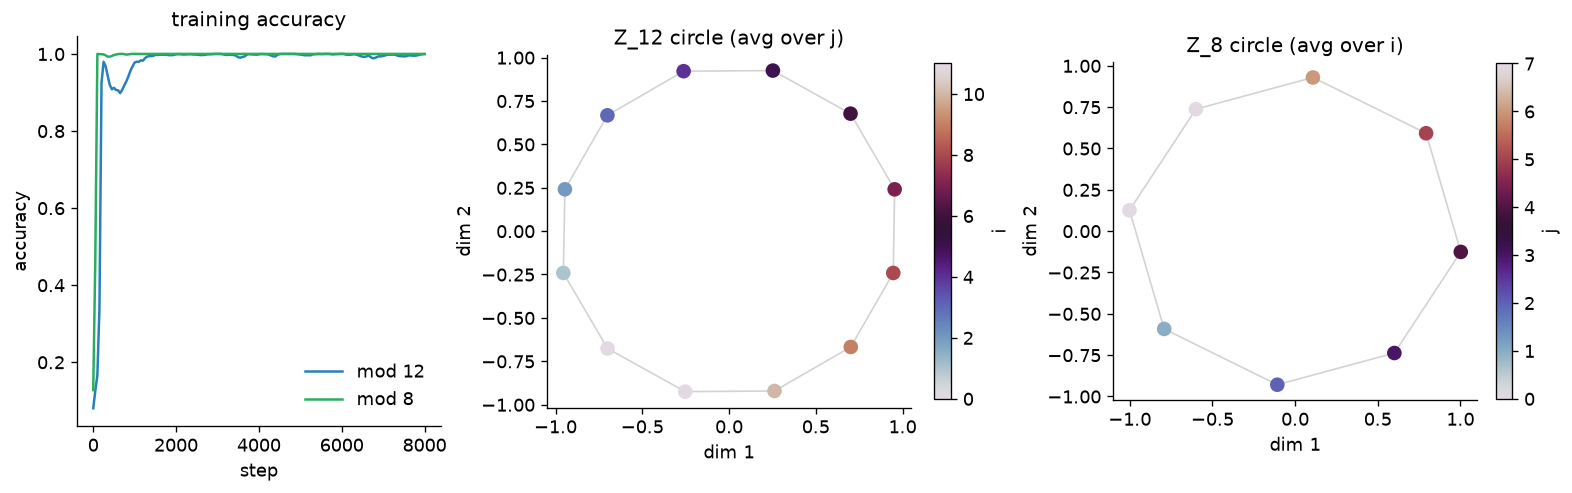

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4))

ax[0].plot(histt[:, 0], histt[:, 2], color="#2980b9", label=f"mod {p}")
ax[0].plot(histt[:, 0], histt[:, 3], color="#27ae60", label=f"mod {q}")
ax[0].set(title="training accuracy", xlabel="step", ylabel="accuracy"); ax[0].legend(frameon=False)

# the two factors, isolated: each is a clean circle (other coordinate averaged out)
scatter2d(ax[1], fig, ci2d, np.arange(p), cmap="twilight", clabel="i", xlabel="dim 1", ylabel="dim 2",
          title=f"Z_{p} circle (avg over j)", path=np.argsort(ang_i), s=60)
scatter2d(ax[2], fig, cj2d, np.arange(q), cmap="twilight", clabel="j", xlabel="dim 1", ylabel="dim 2",
          title=f"Z_{q} circle (avg over i)", path=np.argsort(ang_j), s=60)
plt.show()

In [23]:
import plotly.graph_objects as go

# A plain 3-D PCA can't show this torus: it is genuinely 4-D (two circles), and a linear
# projection to 3-D crushes one of them into a segment (a blob, not a donut). Instead use the
# standard *stereographic* map of the flat (Clifford) torus: put each recovered circle-pair on
# the unit 3-sphere, then project from the pole -> a real donut, no hand-picked radii.
w = np.stack([np.cos(th_i), np.sin(th_i), np.cos(th_j), np.sin(th_j)], 1) / np.sqrt(2)
den = 1 - w[:, 3]
X, Y, Z = w[:, 0] / den, w[:, 1] / den, w[:, 2] / den

fig = go.Figure()
# torus mesh: minor circles (fixed i, vary j) + major circles (fixed j, vary i);
# stereographic projection sends circles to circles, so the mesh stays a clean grid of rings
for grp, ang in [(ii, th_j), (jj, th_i)]:
    for g in np.unique(grp):
        o = np.where(grp == g)[0]; o = o[np.argsort(ang[o])]; o = np.r_[o, o[:1]]
        fig.add_trace(go.Scatter3d(x=X[o], y=Y[o], z=Z[o], mode="lines",
                                   line=dict(color="lightgray", width=2), showlegend=False, hoverinfo="skip"))
fig.add_trace(go.Scatter3d(
    x=X, y=Y, z=Z, mode="markers",
    marker=dict(size=4, color=ii, colorscale="Twilight", colorbar=dict(title="i")),
    text=[f"(i={int(i)}, j={int(j)})" for i, j in zip(ii, jj)], hoverinfo="text", showlegend=False))
fig.update_layout(title="stereographic projection of the learned torus (drag to rotate)",
                  scene=dict(aspectmode="data"), width=760, height=640, margin=dict(l=0, r=0, t=40, b=0))
fig  # interactive in Jupyter / VSCode

The embedding is **rank-4** (four near-equal singular values), and averaging out either coordinate isolates a clean **2-D circle** (>0.99 of its variance): one $S^1$ for the $\mathbb Z_p$ part, one for the $\mathbb Z_q$ part — and a product of two circles *is* a **torus**.

A plain 3-D PCA can't display it (the torus is genuinely 4-D; projecting linearly to 3-D collapses one circle into a segment — a blob, not a donut), so the plot above uses **stereographic projection** of the flat (Clifford) torus: a principled 4-D→3-D map using only the recovered circle subspaces, no hand-picked radii. The interlocking mesh — minor circles (fixed $i$) threaded by major circles (fixed $j$), color sweeping $i$ around the big loop — is the torus surface. The product structure of the task becomes a product of circles: the compositional $(Z,\star,\psi)$ case, $Z$ a product group and the geometry the product of the factors' shapes.

## 7. Order-2, relational: kinship — recover the geometry by *reconstruction*

The other order-2 tasks are each generated by a **single symmetric relation** (a group, an order), so their max-margin solution is unique and the **task loss alone pins the geometry**. Kinship is the contrast: input = (person, relation), output = person, but with **many heterogeneous relations over a rigid family graph and no unifying symmetry**. Its conditional is deterministic, so the classification loss fixes only *rankings* — and with no symmetry to pin them, different seeds give different embeddings (cross-seed RSA ≈ 0.3). The geometry isn't recoverable from the task loss alone.

**Fix: reconstruct the conditional tensor instead of classifying from it.** Factorize the relational tensor $T[p_1,\text{rel},p_2] \approx e(p_1)^\top M_{\text{rel}}\, e(p_2)$ — a *tied* entity embedding $e$ with one matrix per relation (the order-2 tensor factorization / RESCAL, Appendix B), fit by least squares with orthonormal $e$ to fix the gauge. Matching the tensor's *values* (every entry, including the zeros) pins the embedding up to rotation → a stable, canonical geometry.

*(One family, not two — two isomorphic families is Hinton's classic setup, but with no cross-family relations they're disconnected copies; that only adds a spurious "which family" axis, so we use one.)*

In [24]:
# --- one family: 10 people, 13 relations ---
ksex = ['M','F','M','F','F','M','M','F','M','F']; kgen = [0,0,1,1,1,1,2,2,2,2]
kshort = ["GF","GM","son","dau","son-wife","dau-hus","s-son","s-dau","d-son","d-dau"]
kpar = {2:{0,1},3:{0,1},6:{2,4},7:{2,4},8:{3,5},9:{3,5}}; ksp = [(0,1),(2,4),(3,5)]; kp = list(range(10))
kparents = {c:set(ps) for c,ps in kpar.items()}
kspouse = {}
for x,y in ksp: kspouse.setdefault(x,set()).add(y); kspouse.setdefault(y,set()).add(x)
kch = {}
for c,ps in kparents.items():
    for q in ps: kch.setdefault(q,set()).add(c)
ksib = {x:({y for q in kparents.get(x,()) for y in kch.get(q,set())} - {x}) for x in kp}
_m = lambda S,g: {y for y in S if ksex[y]==g}
KR = {'father':{x:_m(kparents.get(x,set()),'M') for x in kp},   'mother':{x:_m(kparents.get(x,set()),'F') for x in kp},
      'son':{x:_m(kch.get(x,set()),'M') for x in kp},           'daughter':{x:_m(kch.get(x,set()),'F') for x in kp},
      'husband':{x:_m(kspouse.get(x,set()),'M') for x in kp},   'wife':{x:_m(kspouse.get(x,set()),'F') for x in kp},
      'brother':{x:_m(ksib[x],'M') for x in kp},                'sister':{x:_m(ksib[x],'F') for x in kp},
      'uncle':{x:_m({b for q in kparents.get(x,()) for b in ksib[q]},'M')|{h for q in kparents.get(x,()) for s in _m(ksib[q],'F') for h in _m(kspouse.get(s,set()),'M')} for x in kp},
      'aunt':{x:_m({b for q in kparents.get(x,()) for b in ksib[q]},'F')|{w for q in kparents.get(x,()) for s in _m(ksib[q],'M') for w in _m(kspouse.get(s,set()),'F')} for x in kp},
      'nephew':{x:_m({c for s in ksib[x] for c in kch.get(s,set())},'M') for x in kp},
      'niece':{x:_m({c for s in ksib[x] for c in kch.get(s,set())},'F') for x in kp},
      'cousin':{x:{c for q in kparents.get(x,()) for s in ksib[q] for c in kch.get(s,set())} for x in kp}}
krels = list(KR); nk = 10

# binary relational tensor:  Tk[rel, p1, p2] = 1 if p2 is p1's <rel>
Tk = np.zeros((len(krels), nk, nk))
for ri, rn in enumerate(krels):
    for x, ys in KR[rn].items():
        for y in ys: Tk[ri, x, y] = 1

# recover the person geometry by RECONSTRUCTING the tensor (least squares): T_rel = A R_rel A^T,
# tied entity embedding A + one matrix per relation; orthonormal A fixes the gauge -> canonical.
def rescal(F=4, iters=150, ridge=1e-3, seed=0):
    g = np.random.default_rng(seed); A = np.linalg.qr(g.standard_normal((nk, F)))[0]
    for _ in range(iters):
        Rr = [np.linalg.pinv(A) @ T @ np.linalg.pinv(A).T for T in Tk]
        Num = sum(T @ A @ Rk.T + T.T @ A @ Rk for T, Rk in zip(Tk, Rr))
        Den = sum(Rk @ (A.T @ A) @ Rk.T + Rk.T @ (A.T @ A) @ Rk for Rk in Rr) + ridge * np.eye(F)
        A = np.linalg.qr(Num @ np.linalg.inv(Den))[0]
    return A
Ak = rescal()

iu = np.triu_indices(nk, 1)
def krdm(A):
    Dm = np.sqrt(((A[:, None] - A[None]) ** 2).sum(-1)); return Dm / Dm[iu].mean()
inits = [rescal(seed=s) for s in range(5)]
stab = np.mean([rsa(inits[i], inits[j]) for i in range(5) for j in range(i + 1, 5)])
print(f"{nk} people, {len(krels)} relations, {int(Tk.sum())} facts")
print(f"cross-init RDM-RSA = {stab:+.2f}  (canonical; the task/classification loss gives only ~0.3)")

10 people, 13 relations, 56 facts
cross-init RDM-RSA = +0.98  (canonical; the task/classification loss gives only ~0.3)


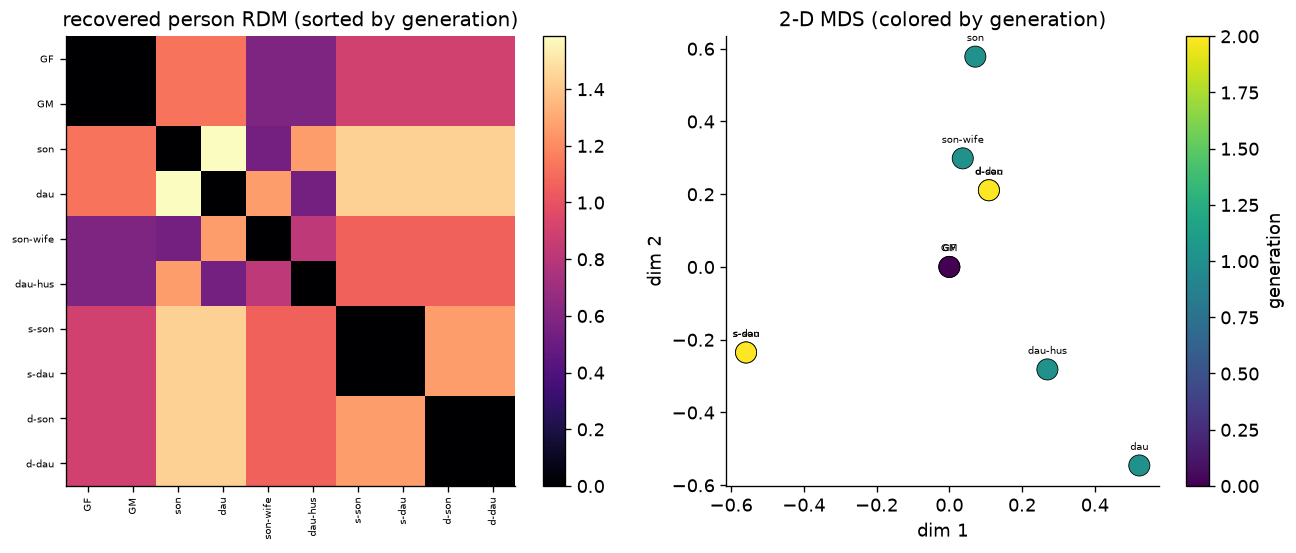

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

# recovered person RDM: sex-swap pairs collapse to distance ~0 (black 2x2 blocks)
order = np.argsort(kgen)                          # group people by generation
Dk = krdm(Ak)[np.ix_(order, order)]
im = ax[0].imshow(Dk, cmap="magma")
ax[0].set(title="recovered person RDM (sorted by generation)")
ax[0].set_xticks(range(nk)); ax[0].set_yticks(range(nk))
ax[0].set_xticklabels([kshort[i] for i in order], rotation=90, fontsize=6)
ax[0].set_yticklabels([kshort[i] for i in order], fontsize=6)
fig.colorbar(im, ax=ax[0], fraction=0.046)

# 2-D MDS -- a lossy projection of the ~4-D geometry; colored by generation
Ac = Ak - Ak.mean(0); Uk, Sk, _ = np.linalg.svd(Ac, full_matrices=False); emb = Uk[:, :2] * Sk[:2]
sc = ax[1].scatter(emb[:, 0], emb[:, 1], c=kgen, cmap="viridis", s=160, edgecolor="k", lw=0.5, zorder=2)
for i, (x, y) in enumerate(emb):
    ax[1].annotate(kshort[i], (x, y), fontsize=6, ha="center", va="center", xytext=(0, 11), textcoords="offset points")
ax[1].set(title="2-D MDS (colored by generation)", xlabel="dim 1", ylabel="dim 2"); ax[1].set_aspect("equal")
fig.colorbar(sc, ax=ax[1], fraction=0.046, label="generation")
plt.show()

The recovered geometry is **canonical** (≈0.98 across inits) and has a specific signature: people who are **sex-swaps of each other collapse to the same point** — grandfather ≡ grandmother, son's-son ≡ son's-daughter, daughter's-son ≡ daughter's-daughter (the black 2×2 blocks in the RDM). The reason: in $e(p_1)^\top M_{\text{rel}}\, e(p_2)$ the **sex distinction is carried by the relation operators** $M_{\text{rel}}$ (father vs mother, brother vs sister), so the *entity* geometry quotients sex out — it encodes structural role (generation, branch), not gender. (`son` ≢ `daughter` because swapping them alone isn't a symmetry — you'd have to swap their spouses too.)

This is the boundary of the clean recipe. For a **single symmetric relation** the *task loss* gives the geometry directly (circle, line, torus): its max-margin solution is unique. For a **heterogeneous relational system** (many relations, no unifying symmetry) the deterministic task loss only fixes *rankings* and leaves the geometry seed-dependent — so you must **reconstruct the conditional's values** (the tied factorization) to pin it, recovering the relational structure *modulo the symmetries the relation-operators absorb*.

## 8. Higher arity: order-3 — the decoder grows, the geometry doesn't

Arity 3: the target is a function of **three** separately-encoded inputs, so the readout is a **trilinear** form,
$$\text{logit}_d(a,b,c)=\sum_{ijk} W_d[i,j,k]\;e(a)_i\,e(b)_j\,e(c)_k,$$
with $W_d$ a $d\times d\times d$ tensor per output class. The embedding $e$ is still one vector per item — only the decoder's order goes up (linear → bilinear → trilinear).

We train it on **three-way modular addition** $d=(a+b+c)\bmod p$. Because addition is abelian, the indicator factors through the *same* Fourier features as the order-2 case,
$$\mathbb 1[a+b+c\equiv d]=\tfrac1p\sum_k \phi_k(a)\phi_k(b)\phi_k(c)\overline{\phi_k(d)},\qquad \phi_k(x)=e^{2\pi ikx/p},$$
so each input should land on **the same circle**, with the trilinear decoder contracting three circle-features instead of two.

In [26]:
p, d, steps, wd, lr = 7, 6, 4000, 3.0, 5e-3
torch.manual_seed(0)
A, B, Cc = torch.meshgrid(torch.arange(p), torch.arange(p), torch.arange(p), indexing="ij")
a, b, c = A.reshape(-1), B.reshape(-1), Cc.reshape(-1)
target = (a + b + c) % p                                    # THREE-WAY modular addition

E3 = torch.nn.Parameter(torch.randn(p, d) * 0.3)
W3 = torch.nn.Parameter(torch.randn(p, d, d, d) * 0.3)      # trilinear decoder: one (d,d,d) tensor per output class
opt = torch.optim.AdamW([E3, W3], lr=lr, weight_decay=wd)
for t in range(steps):
    opt.zero_grad()
    logits = torch.einsum("ni,nj,nk,oijk->no", E3[a], E3[b], E3[c], W3)   # logit_o = W_o(e_a, e_b, e_c)
    loss = torch.nn.functional.cross_entropy(logits, target)
    loss.backward(); opt.step()
print(f"three-way modular addition: accuracy {(logits.argmax(1) == target).float().mean().item():.3f}")

three-way modular addition: accuracy 1.000


singular values [1.52 1.52 0.26 0.03 0.01 0.  ];  dominant freq k=1;  CKA(emb, circle)=0.9997


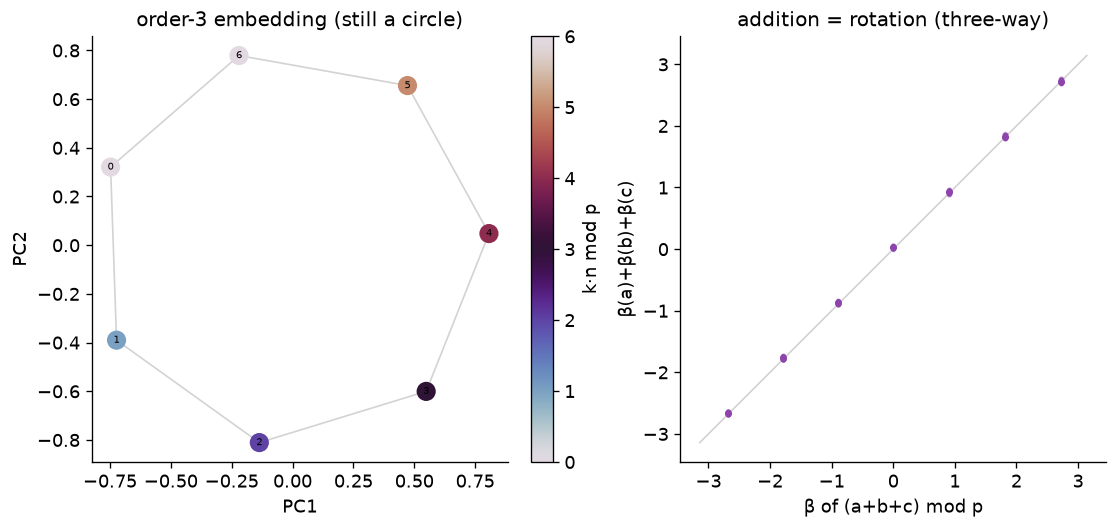

In [27]:
e3 = E3.detach().numpy(); e3c = e3 - e3.mean(0)
U3, S3, _ = np.linalg.svd(e3c, full_matrices=False); pcs3 = U3[:, :2] * S3[:2]
Fp = (np.abs(np.fft.rfft(e3c, axis=0)) ** 2).sum(1)[1:]; k3 = int(np.argmax(Fp)) + 1
nn3 = np.arange(p); circle3 = np.stack([np.cos(2 * np.pi * k3 * nn3 / p), np.sin(2 * np.pi * k3 * nn3 / p)], 1)
print(f"singular values {S3.round(2)};  dominant freq k={k3};  CKA(emb, circle)={cka(e3c, circle3):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(9.5, 4.3))
kn3 = (k3 * nn3) % p
scatter2d(ax[0], fig, pcs3, kn3, cmap="twilight", clabel="k·n mod p", xlabel="PC1", ylabel="PC2",
          title="order-3 embedding (still a circle)", path=np.argsort(kn3), annotate=True, s=110)

# addition = rotation, now three-way:  β(a) + β(b) + β(c) = β((a+b+c) mod p)
ang = np.arctan2(pcs3[:, 1], pcs3[:, 0]); beta = np.angle(np.exp(1j * (ang - ang[0])))
ai, bi, ci = a.numpy(), b.numpy(), c.numpy()
lhs = np.angle(np.exp(1j * (beta[ai] + beta[bi] + beta[ci]))); rhs = beta[(ai + bi + ci) % p]
ax[1].plot([-np.pi, np.pi], [-np.pi, np.pi], color="lightgray", lw=1, zorder=0)
ax[1].scatter(rhs, lhs, s=6, alpha=0.25, color="#8e44ad", zorder=2)
ax[1].set(title="addition = rotation (three-way)", xlabel="β of (a+b+c) mod p", ylabel="β(a)+β(b)+β(c)")
ax[1].set_aspect("equal")
plt.show()

Same **circle** (CKA ≈ 0.99), now read out by a **trilinear** decoder — and the addition-as-rotation identity extends to three terms: $\beta_a+\beta_b+\beta_c=\beta_{(a+b+c)\bmod p}$ (every triple lands on the diagonal). So **arity is the order of the decoder, not the shape of the geometry**: an abelian sum gives a circle at every arity, because it factors through the same Fourier features.

The flip side: a genuinely **3-way-interacting** relation — one that does *not* decompose into pairwise/Fourier terms — would need the full trilinear factorization and could induce a richer geometry. Order-3 is where non-decomposable interactions first appear; additive tasks just don't exercise that freedom.

---
### Takeaway

| | order 1 (lookup) | order ≥2 (combination) |
|---|---|---|
| object | conditional **matrix** $p(y\mid x)$ (co-occurrence) | conditional **tensor** $\log p(c\mid a,b,\dots)$ |
| readout | linear $We(x)$ | multilinear $e(a)^\top M_c e(b)$, trilinear, … |
| geometry from | **closed form** (SVD = classical MDS) | **fit** (deterministic → margin selects the modes) |
| examples here | ring → circle, Gaussian → confusability fan, sphere → sphere | modular → circle, comparison → line, $\mathbb Z_p\times\mathbb Z_q$ → torus, kinship → tree, 3-way add → circle |

Same construction (build the conditional, factorize it so each input is encoded separately, made linearly readable) at every tensor order. **Arity is the dial** — order-1 reads the geometry off the conditional in closed form, order ≥2 has to *manufacture* it through the rate–margin tradeoff, and arity is precisely the **order of the readout** (linear → bilinear → trilinear): §8 shows that pushing to order-3 just raises the decoder while the geometry is unchanged. Within each order, the **symmetry / relation** sets the shape: translation → circle, rotation → sphere (§1, §3); a cyclic sum → circle, an order → line, a product of groups → torus (Appendix D's $(Z,\star,\psi)$).

**When the task loss is enough (§7).** Cases 4–6 and 8 share a deterministic conditional yet train cleanly because each is generated by a *single symmetric* relation, so the max-margin solution is unique and the task loss pins the geometry. Kinship (§7) is the boundary: *many* relations, no symmetry → the task loss fixes only rankings and leaves the geometry seed-dependent. There you must **reconstruct the conditional's values** (the tied tensor factorization), and what you recover is the relational structure *modulo the symmetries the relation-operators absorb* (sex, here). The general rule: the task loss alone suffices when the conditional is **graded**, or **deterministic with a unifying symmetry**; otherwise recover the geometry by reconstructing the conditional.